In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\VORPC\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [4]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
print(df.head())


   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         False                  0  Hi-Fi Speakers  


In [5]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?



In [7]:
frequency_table = df.category.value_counts()

In [8]:
#Frequency table of the product category 
frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [9]:
#top 5 categories 
frequency_table.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [10]:
top_10_catogaries = frequency_table.head(10)

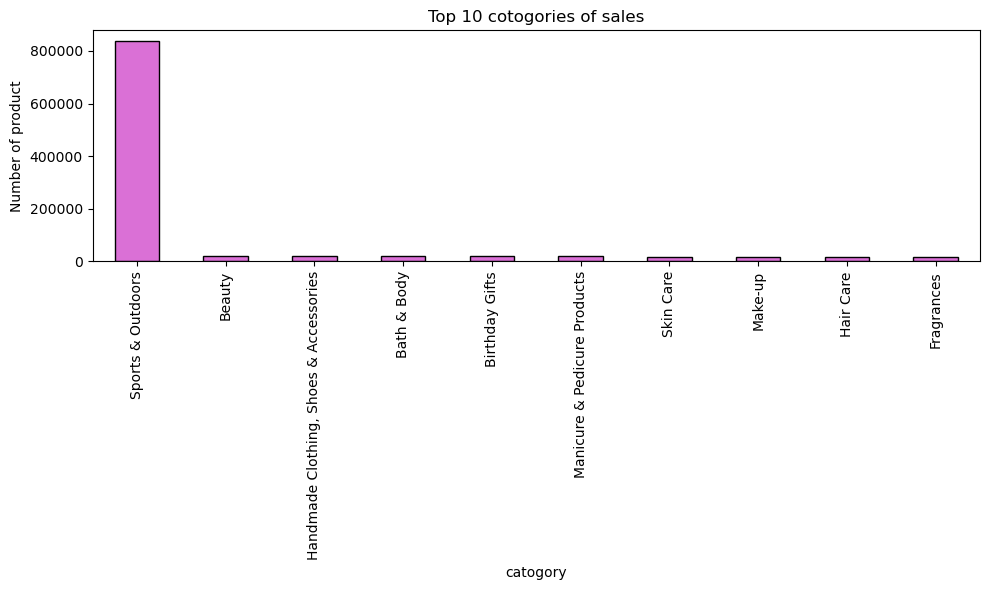

In [11]:
plt.figure(figsize=(10,6))
top_10_catogaries.plot(kind='bar', color='orchid',edgecolor = 'black')
plt.title('Top 10 cotogories of sales')
plt.xlabel('catogory')
plt.ylabel('Number of product')
plt.tight_layout()
plt.show()

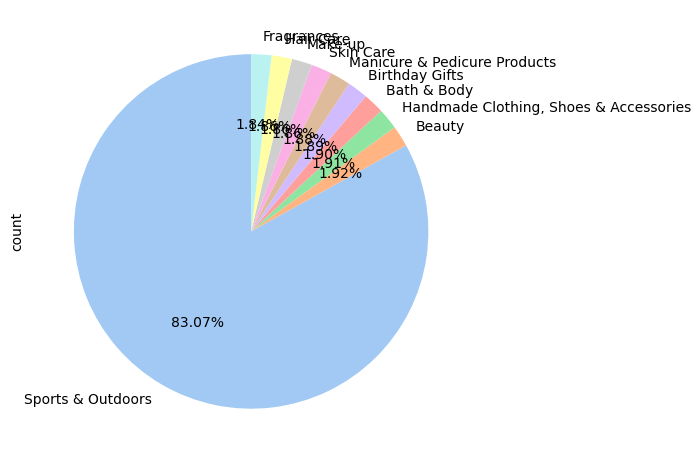

In [12]:
colors = sns.color_palette('pastel')

top_10_catogaries.plot.pie(autopct='%1.2f%%' ,startangle=90, colors=colors)
plt.tight_layout()
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?



In [13]:
mean_price= df['price'].mean()
median_price = df['price'].median()
mode_price= df['price'].mode()
print("mean price:",mean_price,"median price:",median_price,"mode price:",mode_price)
print(mode_price)


mean price: 89.24380943923663 median price: 19.09 mode price: 0    9.99
Name: price, dtype: float64
0    9.99
Name: price, dtype: float64


In [14]:
#non-normal Distribution

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?



In [15]:
price_variance=df['price'].var()
round(price_variance,2)

119445.49

In [16]:
price_std =df['price'].std()
round(price_std,2)

345.61

In [17]:
price_range= df['price'].max() - df['price'].min()
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
price_iqr = Q3 - Q1 

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

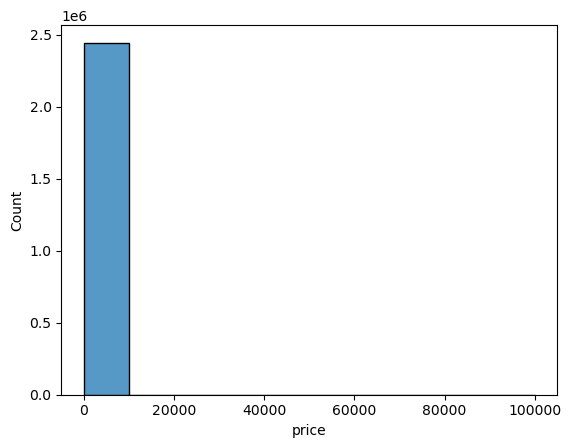

In [18]:
sns.histplot(df.price ,bins =10)
plt.show()

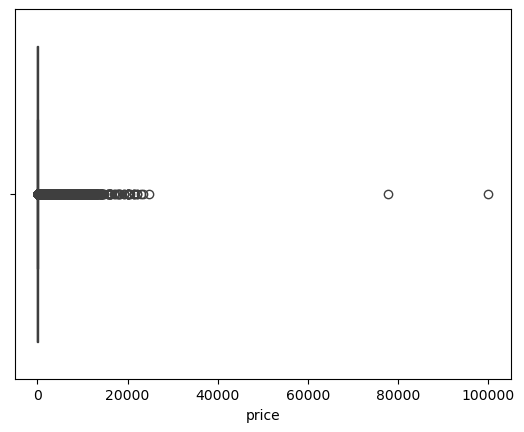

In [25]:
sns.boxplot(x=df['price'])
plt.show()

The histogram and boxplot show that the data distribution is hard to interpret due to two extreme outliers. I will remove them to get a clearer view of the overall price trends.

In [59]:
price_without_outlieners = df['price'] < 45.99


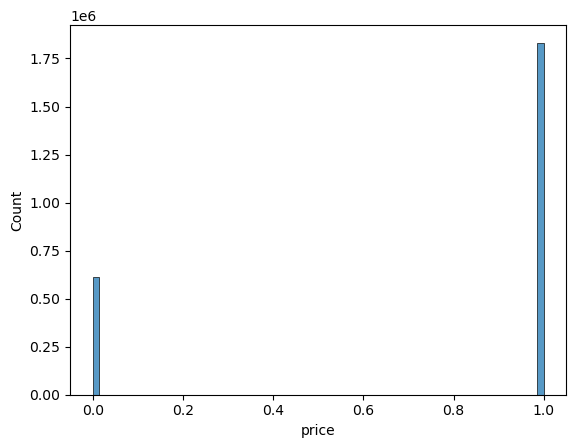

In [60]:
sns.histplot(price_without_outlieners ,bins ="auto")
plt.show()

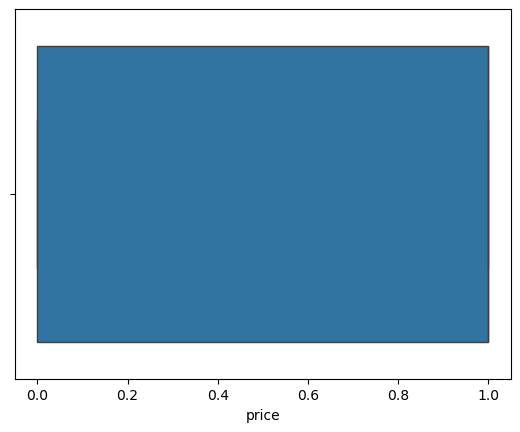

In [61]:
sns.boxplot(x=price_without_outlieners)
plt.show()

In [45]:
round(df.describe(),2)

,uid,stars,reviews,price,boughtInLastMonth
count,2443651.00,2443651.00,2443651.00,2443651.00,2443651.00
mean,1370545.35,2.15,480.63,89.24,25.90
std,816056.17,2.19,5944.12,345.61,240.48
min,1.00,0.00,0.00,0.00,0.00
25%,658921.50,0.00,0.00,9.99,0.00
50%,1349029.00,0.00,0.00,19.09,0.00
75%,2060685.50,4.40,59.00,45.99,0.00
max,2828593.00,5.00,1356658.00,100000.00,50000.00


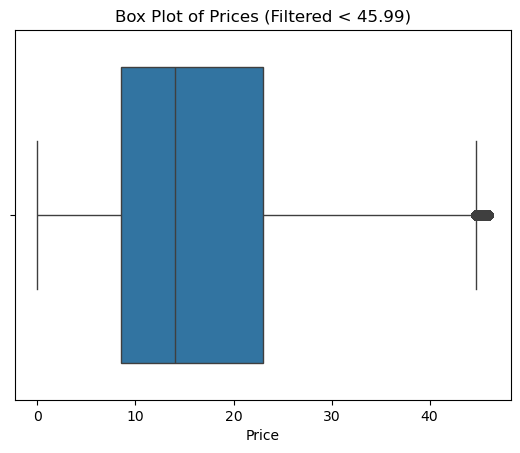

In [66]:
filtered = df[df['price'] < 45.99]
sns.boxplot(x=filtered['price'])
plt.title('Box Plot of Prices (Filtered < 45.99)')
plt.xlabel('Price')
plt.show()



Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Measures of Centrality:

- Calculate the mean, median, and mode for the rating of products.
- How do customers generally rate products? Is there a common trend?

Measures of Dispersion:

- Determine the variance, standard deviation, and interquartile range for product rating.
- Are the ratings consistent, or is there a wide variation in customer feedback?

In [68]:
round(df['stars'].describe(),2)

count    2443651.00
mean           2.15
std            2.19
min            0.00
25%            0.00
50%            0.00
75%            4.40
max            5.00
Name: stars, dtype: float64

"We observe that over 50% of the entries have a rating of 0, which may indicate that products without user reviews are automatically assigned zero stars."

Shape of the Distribution:

- Calculate the skewness and kurtosis for the rating column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?


In [69]:
df['stars'].skew()

np.float64(0.08120735761080985)

In [70]:
df['stars'].kurtosis()

np.float64(-1.9260061280432985)

The stars column shows minimal skewness (≈ 0.08), indicating a nearly symmetric distribution. The kurtosis is strongly negative (≈ -1.93), suggesting light tails and fewer extreme ratings than expected under a normal distribution.


Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?


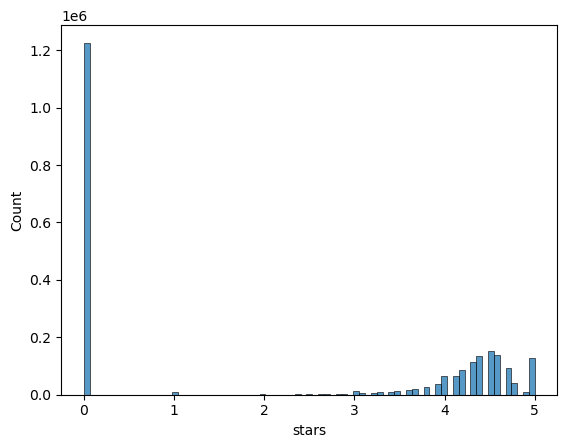

In [72]:
sns.histplot(df.stars , bins="auto")
plt.show()